# Nettoyage et analyse exploratoire de l’occupation du sol

## Objectif
Préparer le jeu `Data_Yakro_New.csv`, contrôler sa qualité et décrire les observations avant la modélisation.


## 1. Importation et aperçu des données


In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import seaborn as sns

from shapely.wkt import loads
import rasterio
from rasterio.plot import show


In [26]:
data=pd.read_csv('Data_Yakro_New.csv')
data.head()

,id,Classes1,geometry,class_name,B1,B2,B3,B4,B5,B6,...,EVI,NDRE,SAVI,NDMI,NDWI,NDWI2,MSI,NDBI,BSI,BI
0,0,3,POINT (226144.65598592497 753082.887017474),Rubber and Other Crops,0.1231,0.1090,0.0979,0.1162,0.1739,0.2023,...,0.100770,0.131802,0.196642,0.031392,-0.396795,0.031392,0.939122,-0.031392,-0.009928,0.146936
1,1,3,POINT (244896.1592880598 760596.3456779018),Rubber and Other Crops,0.1148,0.1007,0.0833,0.1013,0.1755,0.2105,...,0.132572,0.153809,0.246252,0.171316,-0.483569,0.171316,0.707477,-0.171316,-0.113658,0.145435
2,2,1,POINT (234575.58289979704 784710.4423564736),Forest,0.1067,0.0879,0.0698,0.0922,0.1603,0.1894,...,0.125394,0.143239,0.226460,0.144768,-0.507929,0.144768,0.747075,-0.144768,-0.089924,0.129279
3,3,3,POINT (262685.5122421682 754346.432833524),Rubber and Other Crops,0.1193,0.1047,0.0892,0.1063,0.1744,0.2068,...,0.119077,0.143418,0.226135,0.138943,-0.445961,0.138943,0.756010,-0.138943,-0.089061,0.145271
4,4,2,POINT (230657.7821066108 782973.1019210984),Coffee and Cocoa,0.1136,0.1010,0.0813,0.1053,0.1860,0.2198,...,0.141887,0.157227,0.261589,0.155133,-0.517076,0.155133,0.731399,-0.155133,-0.099152,0.152584


In [27]:
#taille du jeu de données    et description du jeu de données
data.shape
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 25 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id          1000 non-null   int64  
 1   Classes1    1000 non-null   int64  
 2   geometry    1000 non-null   str    
 3   class_name  1000 non-null   str    
 4   B1          1000 non-null   float64
 5   B2          1000 non-null   float64
 6   B3          1000 non-null   float64
 7   B4          1000 non-null   float64
 8   B5          1000 non-null   float64
 9   B6          1000 non-null   float64
 10  B7          1000 non-null   float64
 11  B8          1000 non-null   float64
 12  B9          1000 non-null   float64
 13  B10         1000 non-null   float64
 14  NDVI        1000 non-null   float64
 15  EVI         1000 non-null   float64
 16  NDRE        1000 non-null   float64
 17  SAVI        1000 non-null   float64
 18  NDMI        1000 non-null   float64
 19  NDWI        1000 non-null   float64
 20

Le jeu de données contient **1 000 observations et 25 variables**. La colonne `geometry`, qui indique la position spatiale des observations, est initialement stockée sous forme de texte. La classe d’occupation du sol est représentée de deux façons : par son nom dans `class_name` et par un code numérique dans `Classes1`. Nous conserverons ces deux colonnes pour comparer les représentations de la variable cible et évaluer leur effet sur les performances du modèle.


## 2. Nettoyage et préparation des données


### 2.1 Vérification des doublons


In [28]:
nombre_doublons = data.duplicated().sum()
data = data.drop_duplicates().copy()

# verification de l'unicité de la variable geometry egalement
data[data.duplicated(subset=['geometry'])]

print(f"Lignes dupliquées supprimées : {nombre_doublons}")
print(f"Dimensions apres dedoublonnage : {data.shape}")

Lignes dupliquées supprimées : 0
Dimensions apres dedoublonnage : (1000, 25)


nous constatons qu'il n'y pas de doublon de ligne

### 2.2 Préparation de la géométrie


In [29]:

#On s'assure que la colonne est bien lue comme du texte et on enlève les espaces superflus
data['geometry'] = data['geometry'].astype(str).str.strip()

# On convertit le texte WKT "POINT (X Y)" en véritable objet géométrique Shapely
data['geometry'] = data['geometry'].apply(loads)

#verification de premiere etape de la transformation de la variable geometry
print(f"Vérification 1 : {data['geometry'].dtype}")


 #On transforme le DataFrame Pandas en GeoDataFrame pour activer les fonctions spatiales
gdf = gpd.GeoDataFrame(data, geometry='geometry')

 #Vérification du type du jeu definitif
print(f"Vérification 2 : {gdf.info()}")





Vérification 1 : object
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 25 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   id          1000 non-null   int64   
 1   Classes1    1000 non-null   int64   
 2   geometry    1000 non-null   geometry
 3   class_name  1000 non-null   str     
 4   B1          1000 non-null   float64 
 5   B2          1000 non-null   float64 
 6   B3          1000 non-null   float64 
 7   B4          1000 non-null   float64 
 8   B5          1000 non-null   float64 
 9   B6          1000 non-null   float64 
 10  B7          1000 non-null   float64 
 11  B8          1000 non-null   float64 
 12  B9          1000 non-null   float64 
 13  B10         1000 non-null   float64 
 14  NDVI        1000 non-null   float64 
 15  EVI         1000 non-null   float64 
 16  NDRE        1000 non-null   float64 
 17  SAVI        1000 non-null   float64 
 18  NDMI        1000 

In [ ]:
 #Afficher les valeurs distinctes avant nettoyage
from pyparsing import col


display(gdf["class_name"].unique())



# convertir en catégorie
gdf["class_name"] = gdf["class_name"].astype("category")

gdf.info()


## 3. Statistiques descriptives et compréhension des indices


In [58]:
## nettoyage des valeurs numeriques
#  apercu des statistiques du jeu de données
gdf.describe().T

,count,mean,std,min,25%,50%,75%,max
id,1000.0,499.500000,288.819436,0.000000,249.750000,499.500000,749.250000,999.000000
Classes1,1000.0,3.246000,1.391913,1.000000,3.000000,3.000000,3.000000,8.000000
B1,1000.0,0.119123,0.005182,0.106700,0.115200,0.119200,0.122425,0.147700
B2,1000.0,0.104436,0.007063,0.084500,0.100175,0.104100,0.108325,0.145500
B3,1000.0,0.092469,0.013826,0.068000,0.082975,0.090900,0.099900,0.183900
B4,1000.0,0.110509,0.014041,0.063400,0.103300,0.109300,0.117400,0.200600
B5,1000.0,0.168073,0.026774,0.059600,0.157875,0.172900,0.184800,0.229200
B6,1000.0,0.195944,0.035550,0.059200,0.181300,0.201950,0.218000,0.269700
B7,1000.0,0.192639,0.037236,0.051100,0.178400,0.197800,0.214725,0.282400
B8,1000.0,0.220675,0.042405,0.053200,0.204500,0.227550,0.246200,0.306000


 Le tableau ne présente pas de valeurs manquantes.on peut noter que plusieurs  indices comme le NDVI, l’EVI, le NDRE, le SAVI, le NDMI, le NDWI, le NDBI et le BSI  comportent des valeurs négatives. on va donc vérifier leur définition afin de savoir comment les traiter. on notera aussi que NDMI et NDWI2 ont exactement les mêmes statistiques, tandis que NDBI semble être leur opposé.  

## Que nous apprend la littérature ?

| Indice | Nature générale | Précautions d’interprétation |
|---|---|---|
| **NDVI** | Indicateur de la présence et de l’activité de la végétation (Rouse et al., 1974 ; Tucker, 1979). | Peut moins bien différencier des couverts végétaux denses et proches. |
| **EVI** | Indice de végétation conçu pour réduire certaines influences du sol et de l’atmosphère (Huete et al., 2002). | Son interprétation dépend de la formule effectivement utilisée dans le jeu de données. |
| **NDRE** | Indice utilisant la bande red edge, souvent mobilisé pour caractériser la végétation. | Ne constitue pas une mesure directe de la chlorophylle. |
| **SAVI** | Indice de végétation conçu pour limiter l’influence du sol, notamment lorsque le couvert végétal est clairsemé (Huete, 1988). | Son interprétation dépend du paramètre utilisé dans son calcul. |
| **NDMI** | Indice couramment utilisé pour étudier l’humidité de la végétation. | Vérifier les bandes utilisées : les indices portant des noms proches peuvent avoir des définitions différentes. |
| **NDWI** | Indice pouvant servir à mettre en évidence l’eau de surface (McFeeters, 1996). |  |
| **NDWI2** | Nom donné à une variante d’indice liée à l’eau dans certains jeux de données. |  |
| **MSI** | Indice généralement associé au stress hydrique de la végétation. |  |
| **NDBI** | Indice souvent utilisé pour repérer les surfaces bâties (Zha et al., 2003). | Peut réagir également aux sols nus ; il ne suffit pas seul à identifier le bâti. |
| **BSI** | Indice utilisé pour mettre en évidence les sols nus. |  |



| Indice | Plage indicative | Interprétation possible d’une valeur négative |
|---|---:|---|
| **NDVI** | −1 à 1 | Réflectance rouge supérieure au proche infrarouge ; cela peut correspondre à de l’eau ou à une surface peu végétalisée. |
| **EVI** | Généralement proche de −1 à 1 | Peut indiquer une faible activité végétale ou une surface non végétalisée. |
| **NDRE** | −1 à 1 | Peut correspondre à une végétation peu développée ou à une surface non végétalisée. |
| **SAVI** | Dépend du paramètre utilisé ; souvent proche de −1 à 1 | Peut refléter une faible couverture végétale ou l’influence du sol. |
| **NDMI** | −1 à 1 | Peut signaler une faible humidité de la végétation ou une surface sèche. |
| **NDWI** | −1 à 1 pour les variantes normalisées | Le sens dépend de la variante : une valeur négative ne signifie pas la même chose pour toutes les définitions du NDWI. |
| **NDBI** | −1 à 1 pour les variantes normalisées | Peut correspondre à une végétation ou à une surface non bâtie, selon les bandes utilisées. |
| **BSI** | Dépend de la formule | Peut indiquer une faible réponse relative des sols nus |
| **MSI** | Généralement positif | couramment calculé comme un rapport de réflectances. |
| **BI** | Pas de plage universelle | L’interprétation dépend de la définition de cet indice.|

la littérature en télédétection note que beaucoup d’indices dérivés des mêmes bandes sont très corrélés, ce qui ajoute peu d’information.


### 3.1 Traitement des indices redondants


de ce fait on va supprimer  la variable redondante   NDWI2 et NDBI  
un retour dans le describe permet de noter que les plages sont respectés. il nous reste à voir aussi les valeurs aberantes

In [59]:
data=data.drop(["NDWI2","NDBI"], axis=1)
data.shape

(1000, 23)

## 4. Première analyse exploratoire


### 4.1 Répartition des classes


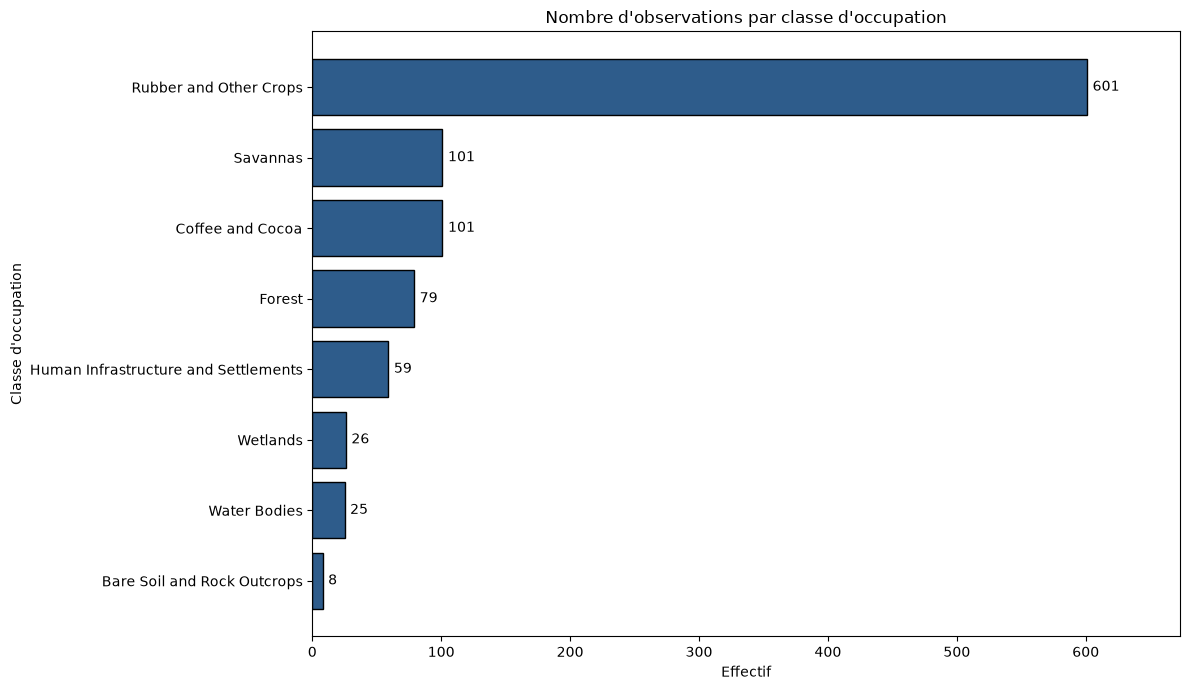

In [30]:

# Effectifs par classe d’occupation, du plus faible au plus élevé
effectifs = gdf["class_name"].value_counts().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(
    effectifs.index.astype(str),
    effectifs.values,
    color="#2e5c8b",
    edgecolor="black",
)

ax.set_title("Nombre d’observations par classe d’occupation")
ax.set_xlabel("Effectif")
ax.set_ylabel("Classe d’occupation")
ax.bar_label(bars, fmt="%d", padding=4)
ax.margins(x=0.12)

plt.tight_layout()
plt.show()



La figure présente la répartition des 1 000 observations selon huit classes d’occupation des sols. La classe Rubber and Other Crops domine largement avec 601 observations (60,1 %), suivie de Savannas et Coffee and Cocoa, qui comptent chacune 101 observations (10,1 %). Les autres classes sont moins représentées, notamment Wetlands (2,6 %), Water Bodies (2,5 %) et Bare Soil and Rock Outcrops (0,8 %).
Cette répartition révèle un déséquilibre important entre les classes. Lors de l’apprentissage du réseau de neurones artificiels (ANN), ce déséquilibre pourrait favoriser la classe majoritaire au détriment des classes minoritaires.

## interpretation a faire ( on constate deja le desequilibre de classe)

### 4.2 Répartition spatiale des observations


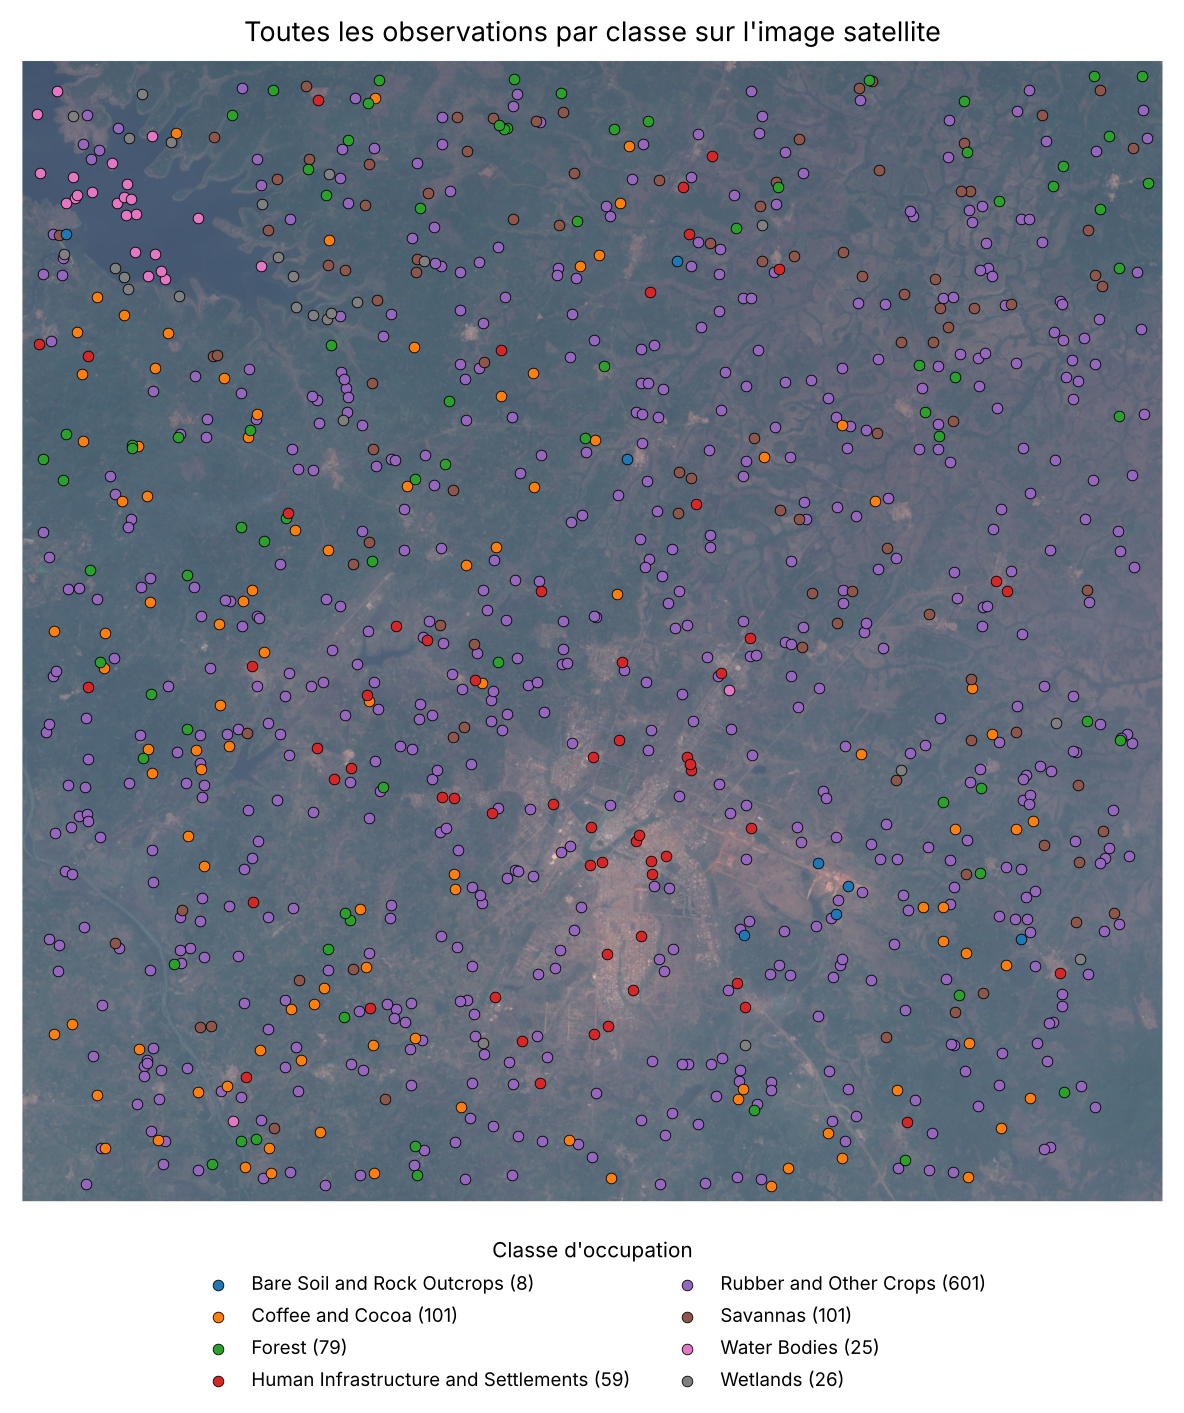

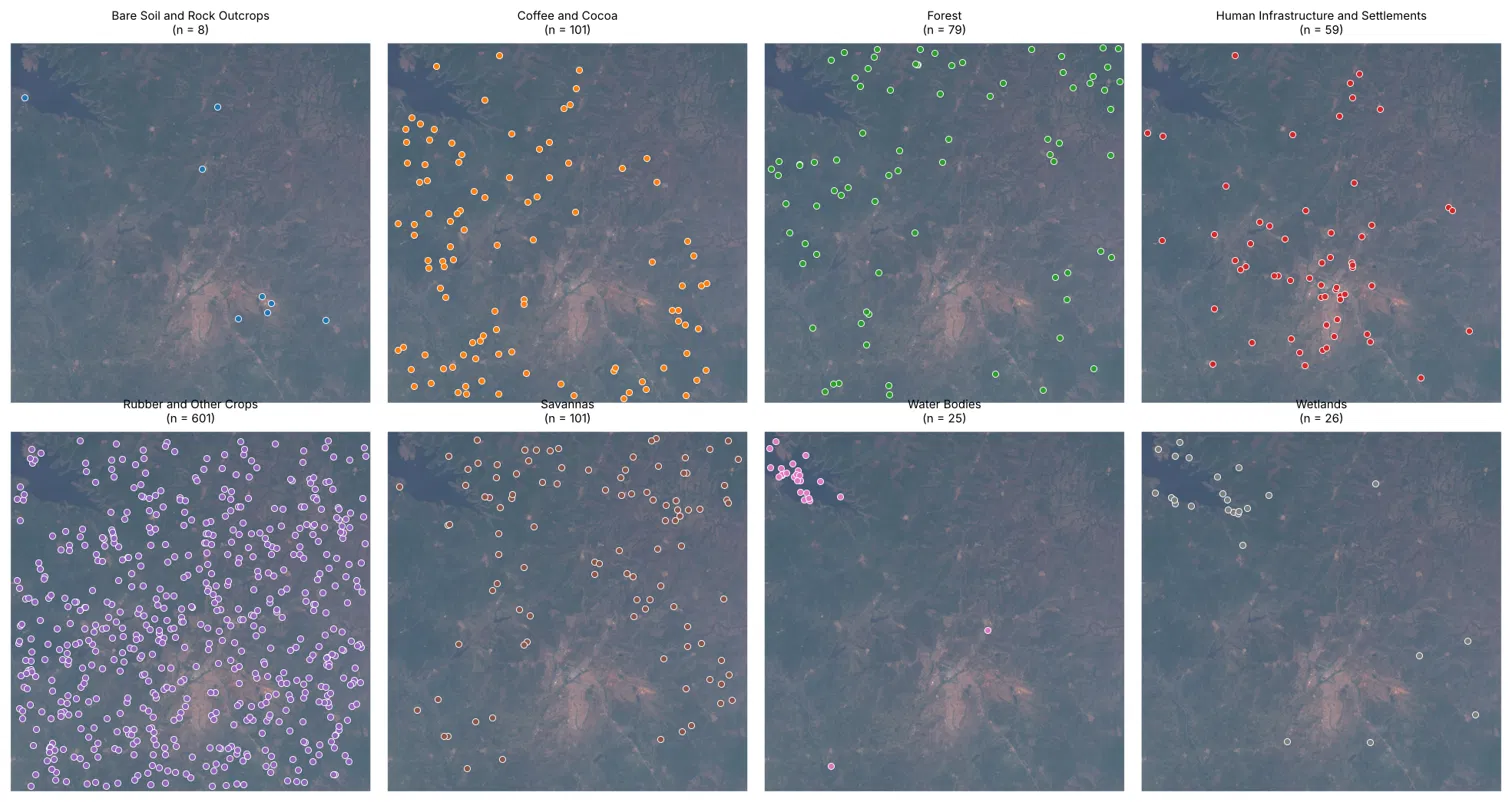

 Un zoom sur chaque classe confirme le commentaire precedent. la classe majoritaire, « Rubber and Other Crops » regroupe l’hévéa et d’autres cultures, ce qui, avec son poids, explique qu’on la retrouve un peu partout sur la zone. Pour les autres classes, chaque observation se situe globalement dans la zone attendue : l’eau et les zones humides autour du lac au nord-ouest, le bâti sur Yamoussoukro et ses axes, le sol nu dans la zone dénudée à l’est de la ville. Forest, Coffee and Cocoa et Savannas se regroupent par secteur (la forêt surtout au nord de la ville).

Deux observations étiquetées Water Bodies attirent l’attention, car elles se trouvent en terre ferme, loin du lac. Le zoom montre que l’une est proche d’un petit cours d’eau. Pour l’autre, il est impossible de le preciser a l'oeil nu, il peut etre un lac artificiel.

Les zones d’habitation ne correspondent pas toujours à du sol nu : plusieurs observations de la classe Human Infrastructure se trouvent en zone boisée, à proximité de cours d’eau et de plantations.On peut faire l’hypothèse que ces implantations profitent de la complémentarité des ressources (eau, terres cultivables, bois)

### 4.3 Exploration des valeurs extrêmes


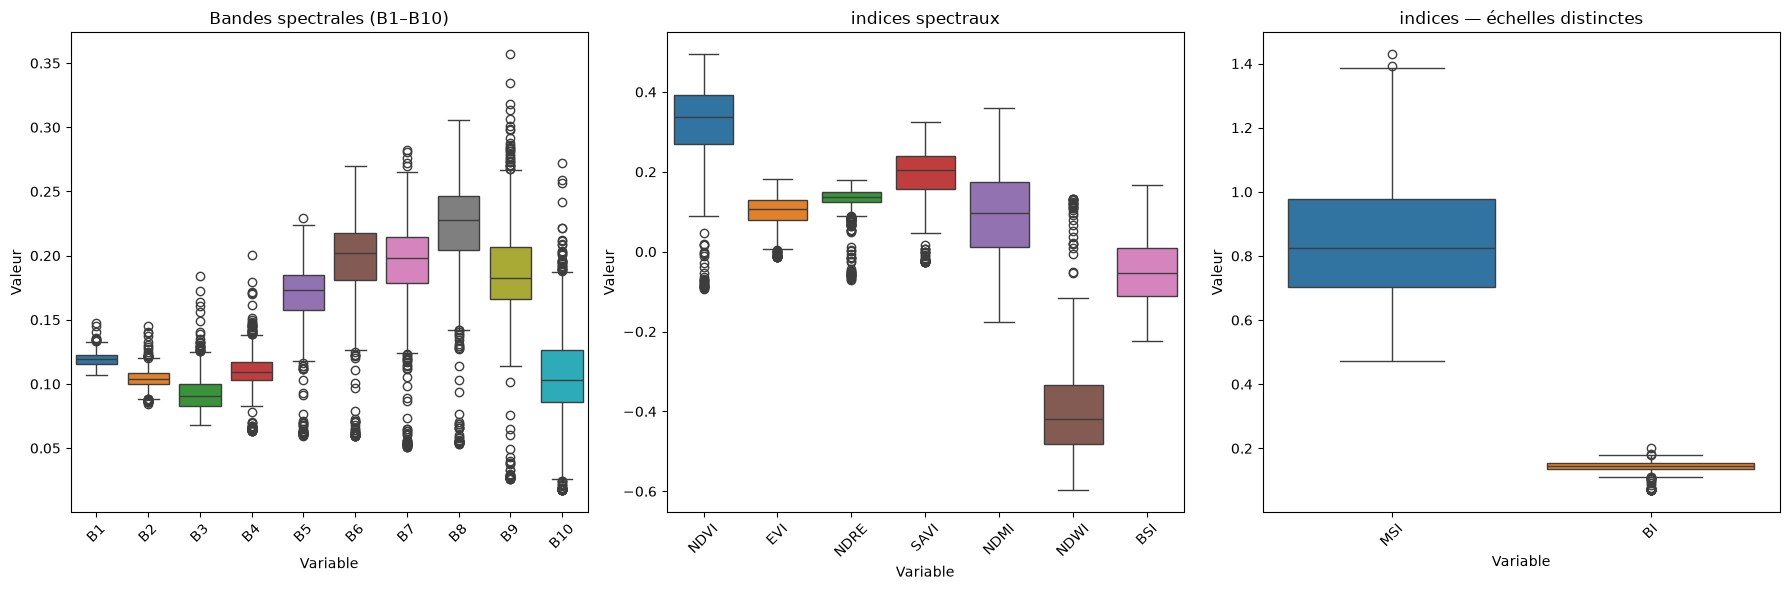

In [61]:
#valeur aberantes numeriques  a examiner 


# Regrouper les variables de plages comparables
groupes = {
    "Bandes spectrales (B1–B10)": [f"B{i}" for i in range(1, 11)],
    "indices spectraux": [
        "NDVI", "EVI", "NDRE", "SAVI", "NDMI", "NDWI", "BSI"
    ],
    "indices — échelles distinctes": ["MSI", "BI"],
}

# Garder uniquement les colonnes présentes dans le jeu de données
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (titre, variables) in zip(axes, groupes.items()):
    variables = [col for col in variables if col in data.columns]

    if variables:
        sns.boxplot(data=data[variables], ax=ax)
        ax.set_title(titre)
        ax.set_xlabel("Variable")
        ax.set_ylabel("Valeur")
        ax.tick_params(axis="x", rotation=45)
    else:
        ax.set_visible(False)

plt.tight_layout()
plt.show()


In [ ]:
# interpretation à faire

### 4.4 Corrélation entre les indices construits


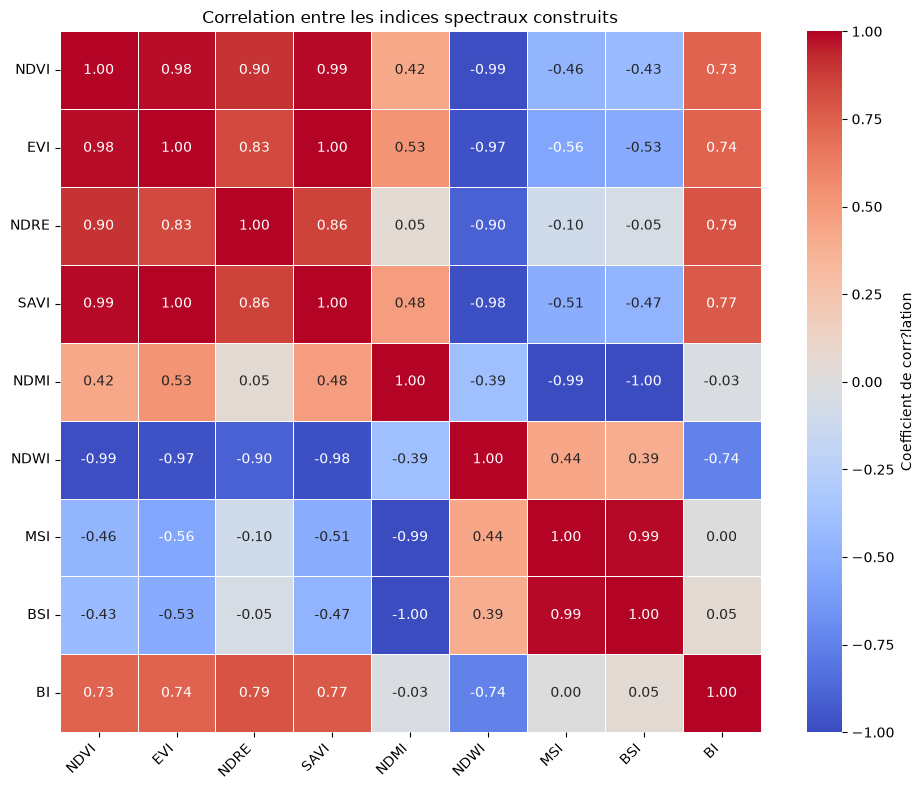

In [16]:
# Matrice de corrélation des indices spectraux construits
indicateurs_construits = [
    "NDVI", "EVI", "NDRE", "SAVI", "NDMI", "NDWI", "MSI", "BSI", "BI"
]
correlations = data[indicateurs_construits].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Coefficient de corrélation"},
    ax=ax,
)

ax.set_title("Corrélation entre les indices spectraux construits")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Bilan et suite du projet

Cette première phase couvre le chargement, les contrôles de qualité, la préparation des géométries et l’exploration descriptive des classes, des variables numériques et des indices construits. Les décisions de traitement supplémentaires (notamment sur les valeurs extrêmes et le déséquilibre des classes) restent à justifier à partir des résultats avant toute modélisation.
